# Multi-Vector RAG 파이프라인 구축

이 노트북에서는 PDF 문서를 대상으로 **Multi-Vector Retriever 패턴**(요약은 검색 전용, 원본은 답변 생성 전용)의 Multimodal RAG 파이프라인을 직접 구축합니다.

- 검색 대상 문서: `data/korea_travel_guide_book.pdf` (사진과 레이아웃 비중이 높은 관광 가이드북)
- 참고: [Multimodal RAG.md](../../Multimodal%20RAG.md)


## 1. 기존 RAG의 한계 복습
- 문서를 텍스트로만 추출하면 표·차트·이미지에서 정보가 손실됨
- 관광 가이드북처럼 **사진 한 장이 핵심 정보**인 문서는 텍스트 추출만으로 내용을 온전히 살릴 수 없음
- 해결책: 페이지를 **이미지 그대로** 색인하고, 검색에는 이미지를 요약한 텍스트를 사용


In [1]:
from pathlib import Path

import chromadb
import fitz  # PyMuPDF
from tqdm import tqdm

from rag_utils import summarize_image, embed_text, show

PDF_PATH = Path("./data/korea_travel_guide_book.pdf")
PAGE_IMAGE_DIR = Path("./pages/korea_travel_guide_book")
PAGE_IMAGE_DIR.mkdir(parents=True, exist_ok=True)


## 2. PDF 페이지를 이미지로 렌더링

Multimodal RAG의 첫 단계는 PDF 각 페이지를 이미지(PNG)로 저장하는 것입니다. 여기서는 **PyMuPDF(fitz)**로 렌더링합니다(`pdf2image`보다 의존성이 적음).


In [2]:
doc = fitz.open(PDF_PATH)

page_image_paths = []
for i, page in enumerate(doc):
    pix = page.get_pixmap(dpi=150)  # dpi가 높을수록 선명하지만 요약/QA 비용도 증가
    image_path = PAGE_IMAGE_DIR / f"page_{i:02d}.png"
    pix.save(image_path)
    page_image_paths.append(image_path)

print(f"총 {len(page_image_paths)}개 페이지를 이미지로 렌더링했습니다.")


총 15개 페이지를 이미지로 렌더링했습니다.


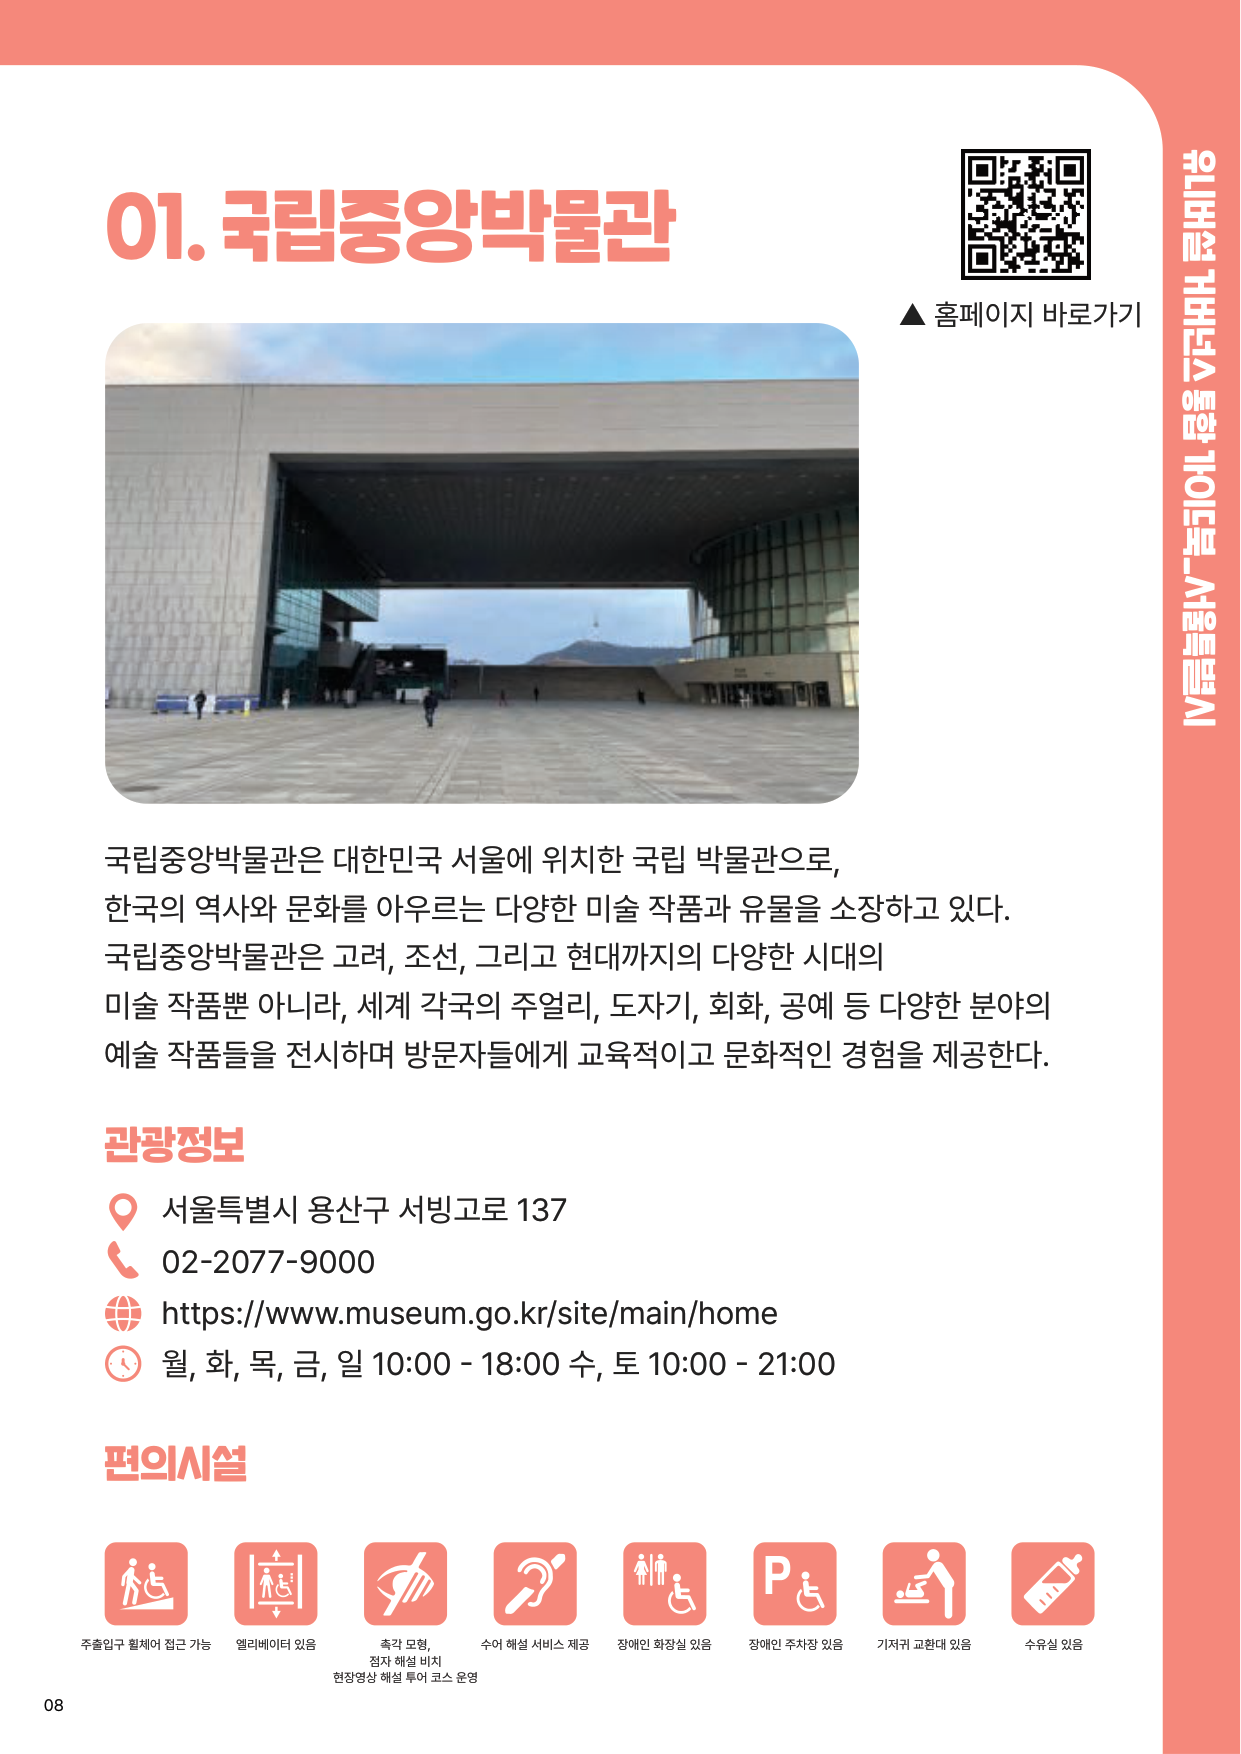

In [3]:
# 페이지 미리보기 (03. 서울한방진흥센터)
show(page_image_paths[3])


## 3. Multi-Vector Retriever 구조
- **Vector Store (Chroma)**: 각 페이지 이미지를 VLM으로 요약한 텍스트의 임베딩만 저장 → 검색 전용
- **Document Store**: 페이지 원본 이미지 경로를 `doc_id` 기준으로 보관 → 답변 생성 전용
- 검색 시 요약으로 매칭 → 매칭된 `doc_id`로 원본 이미지를 꺼내 VLM에 전달


In [4]:
SUMMARY_INSTRUCTION = (
    "이 관광 가이드북 페이지 이미지를 검색에 활용할 수 있도록 아래 형식 그대로 요약해줘.\n"
    "각 필드는 이미지에 실제로 나온 내용만 적고, 언급이 없으면 '정보 없음'이라고 적어줘.\n\n"
    "페이지유형: (이 페이지가 하나의 특정 장소를 소개하는 상세 페이지면 '상세', "
    "여러 장소나 기관을 나열/소개하는 목차·개요·표지 페이지면 '개요'라고 적어줘)\n"
    "장소명: (페이지가 다루는 장소명. 여러 장소를 나열하는 개요 페이지면 목록)\n"
    "특징: (핵심 특징 1~2문장)\n"
    "편의시설: (주차, 유모차 대여, 수유실, 카페 등 일반 편의시설)\n"
    "접근성: (휠체어/장애인 이용 가능 여부를 명시적으로 적어줘. 예: '휠체어 접근 가능', '장애인 편의시설 있음', '정보 없음')\n"
    "운영정보: (운영시간, 주소 등 있는 경우만)"
)

page_summaries = []
for image_path in tqdm(page_image_paths, desc="페이지 요약 생성"):
    summary = summarize_image(image_path, SUMMARY_INSTRUCTION)
    page_summaries.append(summary)

page_summaries[3]


페이지 요약 생성: 100%|██████████| 15/15 [01:02<00:00,  4.14s/it]


'페이지유형: 상세  \n장소명: 국립중앙박물관  \n특징: 한국의 역사와 문화를 아우르는 다양한 미술 작품과 유물을 소장하고 있으며, 교육적이고 문화적인 경험을 제공한다.  \n편의시설: 주차 가능, 유모차 대여, 수유실, 카페 있음  \n접근성: 휠체어 접근 가능  \n운영정보: 월, 화, 목, 금, 일 10:00 - 18:00 / 수, 토 10:00 - 21:00, 서울특별시 용산구 서빙고로 137, 02-2077-9000'

In [5]:
# doc_id마다 원본 이미지 경로 + 페이지 번호를 매핑 (Document Store 역할)
doc_ids = [f"page_{i:02d}" for i in range(len(page_image_paths))]

document_store = {
    doc_id: {"image_path": str(image_path), "page": i}
    for i, (doc_id, image_path) in enumerate(zip(doc_ids, page_image_paths))
}


In [6]:
# 개요/목차/기관 소개 페이지는 특정 장소에 대한 정보가 없어 검색 결과로 나와도 답변에 쓸 수 없음
# → Vector Store 색인에서는 제외하고, 실제 장소를 다루는 '상세' 페이지만 임베딩한다
def is_detail_page(summary: str) -> bool:
    first_line = summary.strip().splitlines()[0]
    return "상세" in first_line

detail_mask = [is_detail_page(summary) for summary in page_summaries]
detail_doc_ids = [doc_id for doc_id, keep in zip(doc_ids, detail_mask) if keep]
detail_summaries = [summary for summary, keep in zip(page_summaries, detail_mask) if keep]
detail_image_paths = [path for path, keep in zip(page_image_paths, detail_mask) if keep]

skipped_doc_ids = [doc_id for doc_id, keep in zip(doc_ids, detail_mask) if not keep]
print(f"개요/목차 페이지 {len(skipped_doc_ids)}개는 Vector Store 색인에서 제외했습니다: {skipped_doc_ids}")

# 요약 텍스트를 임베딩해 Vector Store(Chroma)에 저장
# metadata에 image_path를 함께 저장해두면 다른 노트북에서도 Document Store를 복원할 수 있음
summary_embeddings = [embed_text(summary) for summary in tqdm(detail_summaries, desc="요약 임베딩")]

client = chromadb.PersistentClient(path="./chroma_db")
collection = client.get_or_create_collection(
    name="travel_guide_pages",
    metadata={"hnsw:space": "cosine"},
)

# 재실행 시 이전에 색인됐을 수 있는 개요 페이지(및 최신화된 상세 페이지)를 모두 지운 뒤 다시 채운다
collection.delete(ids=doc_ids)
collection.add(
    ids=detail_doc_ids,
    embeddings=summary_embeddings,
    documents=detail_summaries,
    metadatas=[
        {"page": page_image_paths.index(image_path), "image_path": str(image_path)}
        for image_path in detail_image_paths
    ],
)

print(f"{collection.count()}개 페이지 요약이 Vector Store에 저장되었습니다.")


개요/목차 페이지 5개는 Vector Store 색인에서 제외했습니다: ['page_00', 'page_01', 'page_02', 'page_08', 'page_14']


요약 임베딩: 100%|██████████| 10/10 [00:04<00:00,  2.22it/s]

10개 페이지 요약이 Vector Store에 저장되었습니다.


## 4. 검색해보기
질문을 임베딩해 유사한 페이지 요약을 검색하고, `doc_id`로 원본 페이지 이미지를 꺼내봅니다.


In [7]:
query = "휠체어를 타고 이용할 수 있는 관광지를 알려줘"
query_embedding = embed_text(query)

results = collection.query(query_embeddings=[query_embedding], n_results=3)

for doc_id, summary, distance in zip(
    results["ids"][0], results["documents"][0], results["distances"][0]
):
    print(f"[{doc_id}] 거리={distance:.4f}")
    print(summary)
    print()


[page_05] 거리=0.6346
페이지유형: 상세  
장소명: 서울한방진흥센터  
특징: 한방 문화를 쉽게 접할 수 있도록 조성된 한방 복합문화 체험시설이다. 다양한 프로그램을 통해 한방 대중화에 기여하고 있다.  
편의시설: 주차 가능, 유모차 대여, 수유실, 카페 있음  
접근성: 휠체어 접근 가능  
운영정보: 하절기 (3~10월) 10:00 - 18:00, 동절기 (12~2월) 10:00 - 17:00, 주소: 서울특별시 동대문구 약령중앙로 26, 전화: 02-969-9241, 웹사이트: https://kmedi.ddm.go.kr/

[page_13] 거리=0.6829
페이지유형: 상세  
장소명: 청라호수공원  
특징: 다양한 수경 시설을 갖춘 친수공간으로, 새로운 패러다임을 제시하는 공간이다. 드라마 <더 글로리>의 세명이 바둑공원에서 촬영되었다.  
편의시설: 주차할 수 있음, 유모차 대여 있음, 장애인 편의시설 있음  
접근성: 휠체어 접근 가능  
운영정보: 인천광역시 서구 크리스탈로 59 (경서동), 032-456-2749, https://www.insiseol.or.kr/park/cheongna, 상시 개방 / 연중무휴

[page_12] 거리=0.6910
페이지유형: 상세  
장소명: 옥토끼우주센터  
특징: 국내 최초 항공우주과학 테마파크로, 항공우주 관련 자료를 수집하고 교육 프로그램을 운영한다. 어린이를 위한 체험기구와 교육 프로그램이 개발되어 있다.  
편의시설: 주차 가능, 유모차 대여 있음, 장애인 편의시설 있음, 수유실 있음  
접근성: 휠체어 접근 가능  
운영정보: 평일 10:00 - 17:30, 주말 09:30 - 19:00, 주소: 인천광역시 강화군 불은면 강화동로 403, 전화: 032-937-6917~9, 웹사이트: http://www.oktokki.com



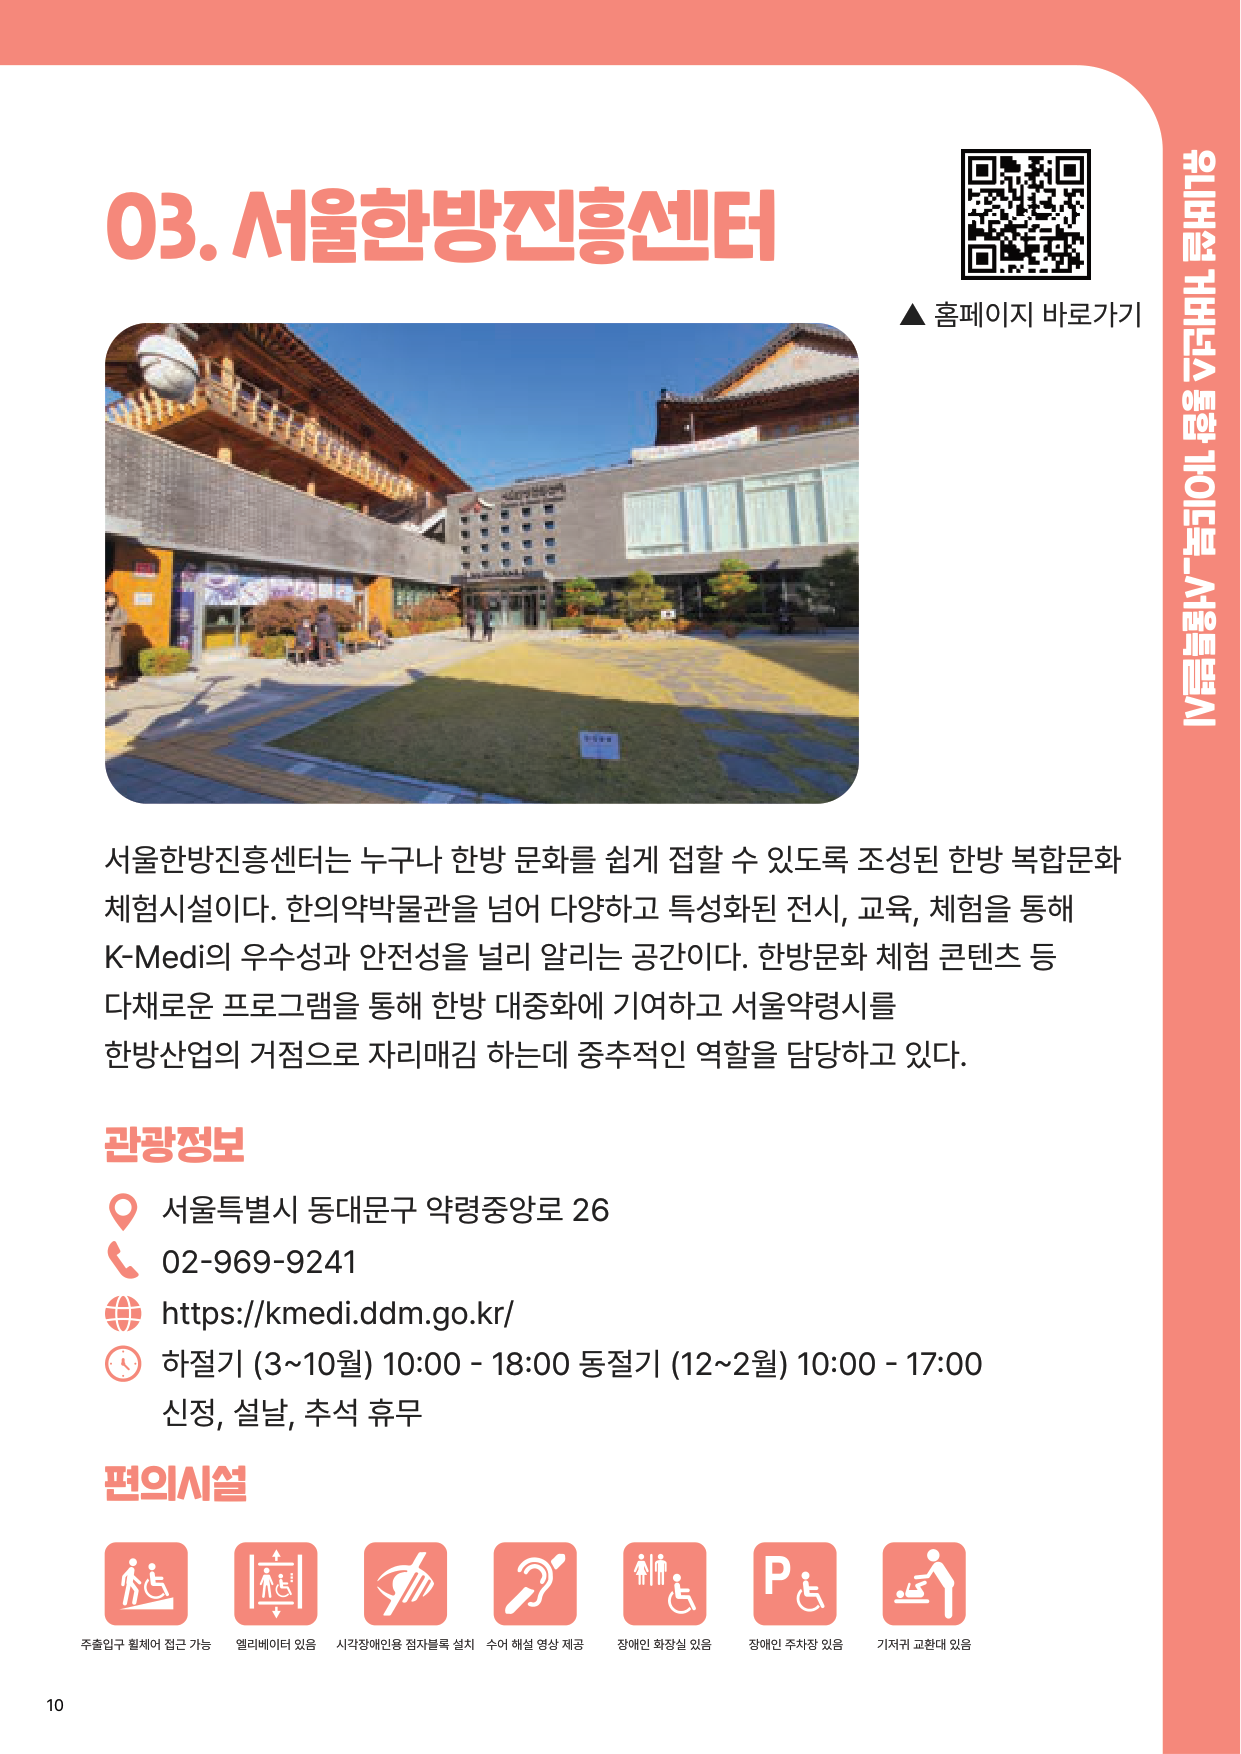

In [8]:
# 검색 1등 페이지의 원본 이미지를 Document Store에서 꺼내 확인
top_doc_id = results["ids"][0][0]
show(document_store[top_doc_id]["image_path"])


이 노트북에서 만든 `travel_guide_pages` 컬렉션(Vector Store)은 다음 노트북 **`2. PDF·이미지 질의응답.ipynb`**에서 그대로 이어서 사용합니다.